# CSE-438 Image Processing

## Project

**Aligned RGB and Multispectral UAV Imagery for Semantic Segmentation of Weedy Rice**

---

## Notebook 0

**Dataset Exploration & Quality Assurance (EDA + QA)**

---

### Framework
- PyTorch

### Platform
- Kaggle

### Dataset
- Weedy Rice RGBMS Dataset (Official Mendeley Dataset)

---

## Objective

The objective of this notebook is to verify the integrity of the dataset before model training. This includes validating the folder structure, checking the train/validation/test splits, visualizing RGB images and segmentation masks, analyzing image statistics, and preparing a reusable PyTorch dataset pipeline for subsequent semantic segmentation models.

---

## Team Members

- Member 1:
- Member 2:
- Member 3:

#  Notebook 0

# Part A — Exploratory Data Analysis (EDA)

Sections 1–12

---



# 1. Import Required Libraries

## Objective

This section imports all Python libraries required for data loading, image processing, visualization, deep learning, and reproducibility throughout the project.

In [1]:
# ==========================================================
# 1. Import Required Libraries
# ==========================================================

# Standard Libraries
import os
import random
from pathlib import Path

# Numerical Computing
import numpy as np
import pandas as pd

# Image Processing
import cv2
from PIL import Image

# Visualization
import matplotlib.pyplot as plt

# Progress Bar
from tqdm import tqdm

# PyTorch
import torch
from torch.utils.data import Dataset, DataLoader

# Display Settings
plt.rcParams["figure.figsize"] = (8, 6)

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# GPU Seed (if GPU is available)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("=" * 60)
print(" Libraries Imported Successfully")
print("=" * 60)

print(f"PyTorch Version : {torch.__version__}")
print(f"CUDA Available  : {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"GPU Name        : {torch.cuda.get_device_name(0)}")

print(f"Random Seed     : {SEED}")

 Libraries Imported Successfully
PyTorch Version : 2.10.0+cu128
CUDA Available  : True
GPU Name        : Tesla T4
Random Seed     : 42


# 2. Environment Verification

## Objective

This section verifies the execution environment used for the project. It records important information such as the Python version, PyTorch version, CUDA availability, GPU model, and operating system to improve reproducibility.

In [2]:
# ==========================================================
# 2. Environment Verification
# ==========================================================

import sys
import platform

print("=" * 60)
print("Environment Information")
print("=" * 60)

print(f"Python Version   : {sys.version.split()[0]}")
print(f"PyTorch Version  : {torch.__version__}")
print(f"Operating System : {platform.system()} {platform.release()}")

print(f"CUDA Available   : {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"GPU              : {torch.cuda.get_device_name(0)}")
    print(f"CUDA Version     : {torch.version.cuda}")

print("=" * 60)

Environment Information
Python Version   : 3.12.13
PyTorch Version  : 2.10.0+cu128
Operating System : Linux 6.12.90+
CUDA Available   : True
GPU              : Tesla T4
CUDA Version     : 12.8


In [3]:
print("/kaggle/input/datasets/subbhaa/weedy-rice-rgbms-dataset")

/kaggle/input/datasets/subbhaa/weedy-rice-rgbms-dataset


# 3. Dataset Attachment & Verification

## Objective

This section connects the notebook to the uploaded Kaggle dataset and verifies that all required files and folders are available before proceeding with data exploration and model development.

In [4]:
# ==========================================================
# 3. Dataset Attachment & Verification
# ==========================================================

from pathlib import Path

# Dataset Root Directory
DATASET_PATH = Path("/kaggle/input/datasets/subbhaa/weedy-rice-rgbms-dataset/WeedyRice-RGBMS-DB")

# Important Subfolders
RGB_PATH = DATASET_PATH / "RGB"
MASK_PATH = DATASET_PATH / "Masks"
MULTISPECTRAL_PATH = DATASET_PATH / "Multispectral"
METADATA_PATH = DATASET_PATH / "Metadata"
OVERLAY_PATH = DATASET_PATH / "Overlay"

print("=" * 60)
print("Dataset Path Verification")
print("=" * 60)

print(f"Dataset Root      : {DATASET_PATH}")
print(f"RGB Folder        : {RGB_PATH.exists()}")
print(f"Masks Folder      : {MASK_PATH.exists()}")
print(f"Multispectral     : {MULTISPECTRAL_PATH.exists()}")
print(f"Metadata Folder   : {METADATA_PATH.exists()}")
print(f"Overlay Folder    : {OVERLAY_PATH.exists()}")

print("=" * 60)

Dataset Path Verification
Dataset Root      : /kaggle/input/datasets/subbhaa/weedy-rice-rgbms-dataset/WeedyRice-RGBMS-DB
RGB Folder        : True
Masks Folder      : True
Multispectral     : True
Metadata Folder   : True
Overlay Folder    : True


In [5]:
from pathlib import Path

root = Path("/kaggle/input/datasets/subbhaa/weedy-rice-rgbms-dataset/WeedyRice-RGBMS-DB")

print("Root exists:", root.exists())
print()

print("Contents of root:")

for item in root.iterdir():
    print(item)

Root exists: True

Contents of root:
/kaggle/input/datasets/subbhaa/weedy-rice-rgbms-dataset/WeedyRice-RGBMS-DB/Metadata
/kaggle/input/datasets/subbhaa/weedy-rice-rgbms-dataset/WeedyRice-RGBMS-DB/RGB
/kaggle/input/datasets/subbhaa/weedy-rice-rgbms-dataset/WeedyRice-RGBMS-DB/train_list.txt
/kaggle/input/datasets/subbhaa/weedy-rice-rgbms-dataset/WeedyRice-RGBMS-DB/readme.md
/kaggle/input/datasets/subbhaa/weedy-rice-rgbms-dataset/WeedyRice-RGBMS-DB/Multispectral
/kaggle/input/datasets/subbhaa/weedy-rice-rgbms-dataset/WeedyRice-RGBMS-DB/test_list.txt
/kaggle/input/datasets/subbhaa/weedy-rice-rgbms-dataset/WeedyRice-RGBMS-DB/val_list.txt
/kaggle/input/datasets/subbhaa/weedy-rice-rgbms-dataset/WeedyRice-RGBMS-DB/Overlay
/kaggle/input/datasets/subbhaa/weedy-rice-rgbms-dataset/WeedyRice-RGBMS-DB/Masks


# 4. Dataset Split Verification

## Objective

The dataset provides official training, validation, and testing lists. This section verifies these files and counts the number of samples in each split before model development.

In [6]:
# ==========================================================
# 4. Dataset Split Verification
# ==========================================================

TRAIN_LIST = DATASET_PATH / "train_list.txt"
VAL_LIST = DATASET_PATH / "val_list.txt"
TEST_LIST = DATASET_PATH / "test_list.txt"

# Read filenames
with open(TRAIN_LIST, "r") as f:
    train_files = [line.strip() for line in f if line.strip()]

with open(VAL_LIST, "r") as f:
    val_files = [line.strip() for line in f if line.strip()]

with open(TEST_LIST, "r") as f:
    test_files = [line.strip() for line in f if line.strip()]

print("=" * 60)
print("Official Dataset Split")
print("=" * 60)

print(f"Training Images   : {len(train_files)}")
print(f"Validation Images : {len(val_files)}")
print(f"Testing Images    : {len(test_files)}")
print(f"Total Images      : {len(train_files) + len(val_files) + len(test_files)}")

print("=" * 60)

# Show a few sample filenames
print("\nSample Training Files:")
for file in train_files[:5]:
    print(file)

Official Dataset Split
Training Images   : 438
Validation Images : 148
Testing Images    : 148
Total Images      : 734

Sample Training Files:
DJI_DateTime_2024_06_02_13_42_0035_lat_10.3040603_lon_105.2619317_alt_20.018m.JPG
DJI_DateTime_2024_06_02_13_42_0036_lat_10.3040274_lon_105.2619303_alt_19.998m.JPG
DJI_DateTime_2024_06_02_13_43_0038_lat_10.3039632_lon_105.2619268_alt_20.009m.JPG
DJI_DateTime_2024_06_02_13_43_0039_lat_10.3039307_lon_105.2619253_alt_20.017m.JPG
DJI_DateTime_2024_06_02_13_43_0040_lat_10.3038985_lon_105.2619236_alt_20.019m.JPG


# 5. RGB Image & Mask Visualization

## Objective

This section loads a sample RGB image and its corresponding segmentation mask from the dataset. The images are displayed side by side to verify that the image-mask pair is correctly matched before training semantic segmentation models.

Theory

Before training a semantic segmentation model, it is essential to visually verify that each RGB image is paired with the correct ground-truth mask. This helps identify mismatched filenames, missing masks, or incorrect image dimensions early in the pipeline.

Sample File
RGB Image : DJI_DateTime_2024_06_02_13_42_0035_lat_10.3040603_lon_105.2619317_alt_20.018m.JPG
Mask      : DJI_DateTime_2024_06_02_13_42_0035_lat_10.3040603_lon_105.2619317_alt_20.018m.png


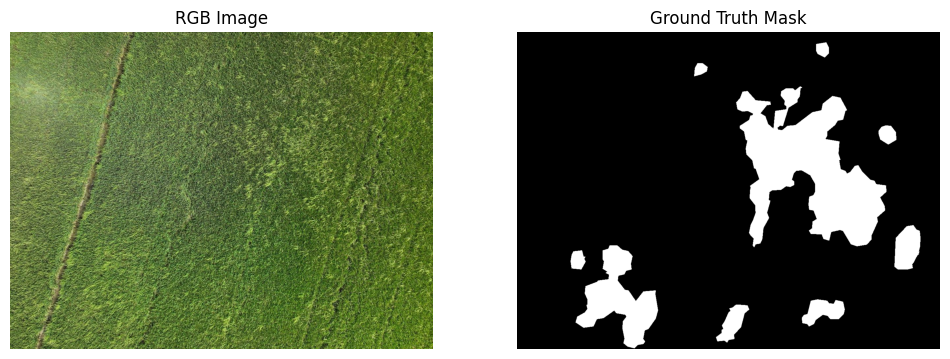

RGB Shape  : (960, 1280, 3)
Mask Shape : (960, 1280)


In [7]:
# ==========================================================
# 5. RGB Image & Mask Visualization
# ==========================================================

# Select the first training image
sample_filename = train_files[0]

# Build image and mask paths
rgb_image_path = RGB_PATH / sample_filename
mask_image_path = MASK_PATH / sample_filename.replace(".JPG", ".png")

print("=" * 60)
print("Sample File")
print("=" * 60)
print("RGB Image :", rgb_image_path.name)
print("Mask      :", mask_image_path.name)
print("=" * 60)

# Load images
rgb_image = Image.open(rgb_image_path)
mask_image = Image.open(mask_image_path)

# Convert to numpy arrays
rgb_np = np.array(rgb_image)
mask_np = np.array(mask_image)

# Display
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.imshow(rgb_np)
plt.title("RGB Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(mask_np, cmap="gray")
plt.title("Ground Truth Mask")
plt.axis("off")

plt.show()

# Print image information
print(f"RGB Shape  : {rgb_np.shape}")
print(f"Mask Shape : {mask_np.shape}")

# 6. Mask Pixel Value Analysis

## Objective

The segmentation masks contain class labels encoded as pixel values. This section identifies all unique pixel values present in the masks to determine the number of segmentation classes and verify the mask encoding format.

In [8]:
# ==========================================================
# 6. Mask Pixel Value Analysis
# ==========================================================

# Load the first mask
sample_mask = np.array(Image.open(mask_image_path))

# Find unique pixel values
unique_values = np.unique(sample_mask)

print("=" * 60)
print("Mask Pixel Value Analysis")
print("=" * 60)

print("Unique Pixel Values:")
print(unique_values)

print("\nNumber of Classes:", len(unique_values))

print("=" * 60)

Mask Pixel Value Analysis
Unique Pixel Values:
[  0 255]

Number of Classes: 2


## 6.1 Dataset-Wide Mask Verification

## Objective

Instead of inspecting a single segmentation mask, this section verifies every mask in the dataset. It confirms that all masks contain only valid class labels and reports the overall set of unique pixel values used throughout the dataset.

In [9]:
# ==========================================================
# 6.1 Dataset-Wide Mask Verification
# ==========================================================

from tqdm import tqdm

all_unique_values = set()

mask_files = sorted(MASK_PATH.glob("*.png"))

print("=" * 60)
print("Scanning All Masks...")
print("=" * 60)

for mask_path in tqdm(mask_files):

    mask = np.array(Image.open(mask_path))

    unique = np.unique(mask)

    all_unique_values.update(unique.tolist())

print("\n" + "=" * 60)
print("Dataset-Wide Mask Verification")
print("=" * 60)

print(f"Total Masks Scanned : {len(mask_files)}")
print(f"Unique Pixel Values : {sorted(all_unique_values)}")
print(f"Number of Classes   : {len(all_unique_values)}")

print("=" * 60)

# Final Verification
expected_values = {0, 255}

if all_unique_values == expected_values:
    print("Verification Passed!")
    print("All masks contain only valid pixel values: {0, 255}")
else:
    print(" Unexpected pixel values detected!")
    print("Please inspect the dataset.")

Scanning All Masks...


100%|██████████| 734/734 [00:26<00:00, 28.19it/s]


Dataset-Wide Mask Verification
Total Masks Scanned : 734
Unique Pixel Values : [0, 255]
Number of Classes   : 2
Verification Passed!
All masks contain only valid pixel values: {0, 255}


# 7. Class Imbalance Analysis

## Objective

Semantic segmentation datasets often contain an unequal distribution of classes. This section calculates the number and percentage of background and weedy rice pixels across the entire dataset to understand class imbalance before model training.

In [10]:
# ==========================================================
# 7. Class Imbalance Analysis
# ==========================================================

from tqdm import tqdm

background_pixels = 0
weed_pixels = 0

mask_files = sorted(MASK_PATH.glob("*.png"))

print("=" * 60)
print("Analyzing Class Distribution...")
print("=" * 60)

for mask_path in tqdm(mask_files):

    mask = np.array(Image.open(mask_path))

    background_pixels += np.sum(mask == 0)
    weed_pixels += np.sum(mask == 255)

total_pixels = background_pixels + weed_pixels

background_percentage = (background_pixels / total_pixels) * 100
weed_percentage = (weed_pixels / total_pixels) * 100

print("\n" + "=" * 60)
print("Class Distribution")
print("=" * 60)

print(f"Background Pixels : {background_pixels:,}")
print(f"Weedy Rice Pixels : {weed_pixels:,}")

print()

print(f"Background (%)    : {background_percentage:.2f}%")
print(f"Weedy Rice (%)    : {weed_percentage:.2f}%")

print()

print(f"Class Ratio (Background : Weed)")
print(f"{background_pixels / weed_pixels:.2f} : 1")

print("=" * 60)

Analyzing Class Distribution...


100%|██████████| 734/734 [00:05<00:00, 129.78it/s]


Class Distribution
Background Pixels : 615,946,184
Weedy Rice Pixels : 285,993,016

Background (%)    : 68.29%
Weedy Rice (%)    : 31.71%

Class Ratio (Background : Weed)
2.15 : 1


# 8. Dataset Statistics

## Objective

This section summarizes the contents of the dataset by counting the number of RGB images, segmentation masks, overlay images, and multispectral image folders. It also verifies that every RGB image has a corresponding segmentation mask.

In [11]:
# ==========================================================
# 8. Dataset Statistics
# ==========================================================

# Count RGB images
rgb_images = sorted(RGB_PATH.glob("*.JPG"))

# Count masks
mask_images = sorted(MASK_PATH.glob("*.png"))

# Count overlay images
overlay_images = sorted(OVERLAY_PATH.glob("*"))

# Count multispectral folders
multispectral_items = sorted(MULTISPECTRAL_PATH.iterdir())

print("=" * 60)
print("Dataset Statistics")
print("=" * 60)

print(f"RGB Images           : {len(rgb_images)}")
print(f"Segmentation Masks   : {len(mask_images)}")
print(f"Overlay Images       : {len(overlay_images)}")
print(f"Multispectral Items  : {len(multispectral_items)}")

print("=" * 60)

# ----------------------------------------------------------
# Verify RGB <-> Mask Matching
# ----------------------------------------------------------

rgb_names = {img.stem for img in rgb_images}
mask_names = {mask.stem for mask in mask_images}

missing_masks = rgb_names - mask_names
missing_rgb = mask_names - rgb_names

print("\nDataset Integrity Check")
print("-" * 60)

print(f"RGB without Mask : {len(missing_masks)}")
print(f"Mask without RGB : {len(missing_rgb)}")

if len(missing_masks) == 0 and len(missing_rgb) == 0:
    print("\n Perfect! Every RGB image has a corresponding mask.")
else:
    print("\n⚠ Dataset mismatch detected.")

print("\n" + "=" * 60)
print("Dataset Completeness")
print("=" * 60)

completeness = (len(mask_images) / len(rgb_images)) * 100

print(f"RGB Images        : {len(rgb_images)}")
print(f"Masks             : {len(mask_images)}")
print(f"Completeness      : {completeness:.1f}%")

Dataset Statistics
RGB Images           : 734
Segmentation Masks   : 734
Overlay Images       : 734
Multispectral Items  : 2936

Dataset Integrity Check
------------------------------------------------------------
RGB without Mask : 0
Mask without RGB : 0

 Perfect! Every RGB image has a corresponding mask.

Dataset Completeness
RGB Images        : 734
Masks             : 734
Completeness      : 100.0%


# 9. Metadata Exploration

## Objective

This section explores the contents of the metadata directory. Before using any metadata for analysis, we inspect the available files and their formats to understand what additional information is provided with the dataset.

In [12]:
# ==========================================================
# 9. Metadata Exploration
# ==========================================================

print("=" * 60)
print("Metadata Folder Contents")
print("=" * 60)

metadata_files = sorted(METADATA_PATH.iterdir())

print(f"Total Metadata Files : {len(metadata_files)}\n")

for file in metadata_files:
    print(file.name)

Metadata Folder Contents
Total Metadata Files : 3

filename_mapping.csv
image_metadata.csv
readme.txt


## 9.1 Metadata File Inspection

## Objective

This section inspects the metadata files by loading them into pandas DataFrames. It reports the number of rows, columns, and available fields without performing detailed analysis. This helps understand the structure of the metadata before using it in later stages.

In [13]:
# ==========================================================
# 9.1 Metadata File Inspection
# ==========================================================

import pandas as pd

# File paths
mapping_file = METADATA_PATH / "filename_mapping.csv"
metadata_file = METADATA_PATH / "image_metadata.csv"

# Load CSV files
mapping_df = pd.read_csv(mapping_file)
metadata_df = pd.read_csv(metadata_file)

print("=" * 60)
print("Filename Mapping")
print("=" * 60)

print(f"Rows    : {mapping_df.shape[0]}")
print(f"Columns : {mapping_df.shape[1]}")

print("\nColumn Names:")

for col in mapping_df.columns:
    print("-", col)

print("\n" + "=" * 60)
print("Image Metadata")
print("=" * 60)

print(f"Rows    : {metadata_df.shape[0]}")
print(f"Columns : {metadata_df.shape[1]}")

print("\nColumn Names:")

for col in metadata_df.columns:
    print("-", col)

print("\n" + "=" * 60)
print("Filename Mapping Preview")
print("=" * 60)
display(mapping_df.head())

print("\n" + "=" * 60)
print("Image Metadata Preview")
print("=" * 60)
display(metadata_df.head())

Filename Mapping
Rows    : 3670
Columns : 2

Column Names:
- original_filename
- standardized_filename

Image Metadata
Rows    : 3670
Columns : 9

Column Names:
- original_filename
- acquisition_date
- time
- latitude
- longitude
- altitude
- camera_model
- sensor_type
- band

Filename Mapping Preview


,original_filename,standardized_filename
0,DJI_20240602134254_0035_D.JPG,DJI_DateTime_2024_06_02_13_42_0035_lat_10.3040...
1,DJI_20240602134254_0035_MS_G.TIF,DJI_DateTime_2024_06_02_13_42_0035_lat_10.3040...
2,DJI_20240602134254_0035_MS_NIR.TIF,DJI_DateTime_2024_06_02_13_42_0035_lat_10.3040...
3,DJI_20240602134254_0035_MS_R.TIF,DJI_DateTime_2024_06_02_13_42_0035_lat_10.3040...
4,DJI_20240602134254_0035_MS_RE.TIF,DJI_DateTime_2024_06_02_13_42_0035_lat_10.3040...



Image Metadata Preview


,original_filename,acquisition_date,time,latitude,longitude,altitude,camera_model,sensor_type,band
0,DJI_20240602134254_0035_D.JPG,2024-06-02,13:42:54,10.30406,105.261932,20.018m,FC6520,RGB,NaN
1,DJI_20240602134254_0035_MS_G.TIF,2024-06-02,13:42:54,10.30406,105.261932,20.018m,MSX01,MS,Green
2,DJI_20240602134254_0035_MS_NIR.TIF,2024-06-02,13:42:54,10.30406,105.261932,20.018m,MSX01,MS,NIR
3,DJI_20240602134254_0035_MS_R.TIF,2024-06-02,13:42:54,10.30406,105.261932,20.018m,MSX01,MS,Red
4,DJI_20240602134254_0035_MS_RE.TIF,2024-06-02,13:42:54,10.30406,105.261932,20.018m,MSX01,MS,RedEdge


# 10. Overlay Visualization

## Objective

This section visualizes an RGB image, its corresponding segmentation mask, and the overlay image. The overlay provides a qualitative assessment of annotation quality by showing the segmentation mask superimposed on the original RGB image.

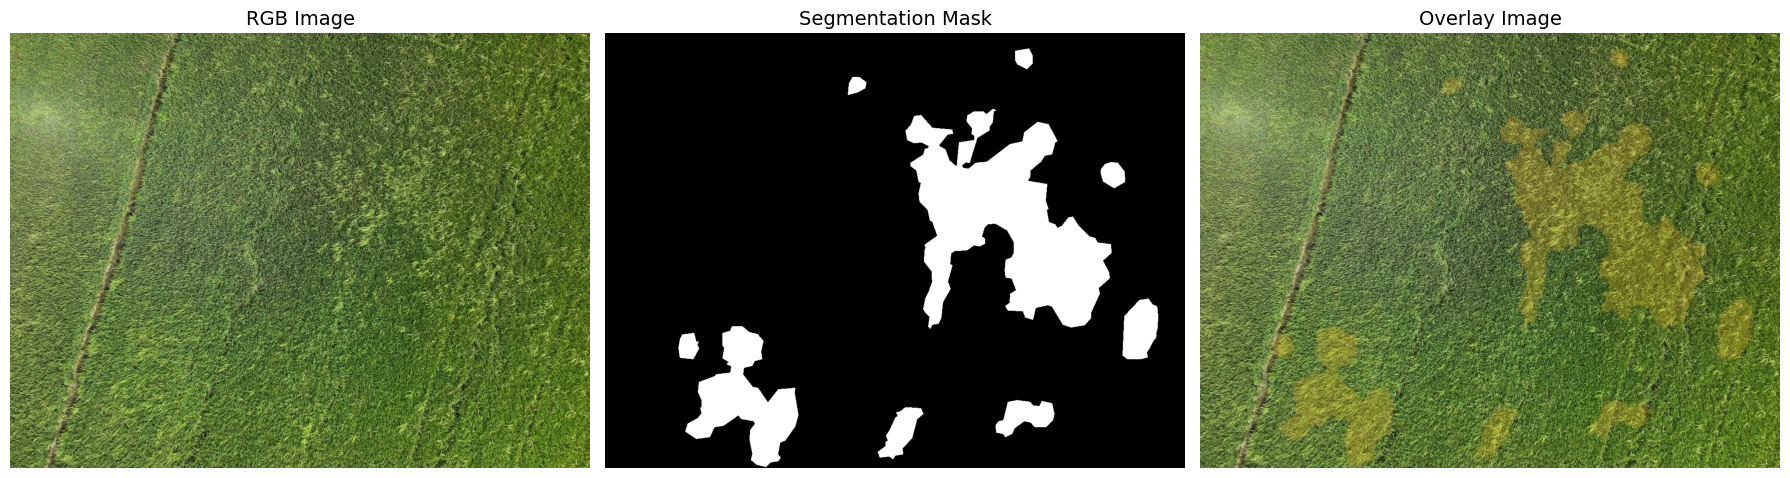

Sample Image : DJI_DateTime_2024_06_02_13_42_0035_lat_10.3040603_lon_105.2619317_alt_20.018m.JPG


In [14]:
## ==========================================================
# 10. Overlay Visualization
# ==========================================================

import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

# Select the first RGB image automatically
rgb_files = sorted(RGB_PATH.glob("*.JPG"))

sample_name = rgb_files[0].name

rgb_path = RGB_PATH / sample_name
mask_path = MASK_PATH / sample_name.replace(".JPG", ".png")
overlay_path = OVERLAY_PATH / sample_name

# Load images
rgb = np.array(Image.open(rgb_path))
mask = np.array(Image.open(mask_path))
overlay = np.array(Image.open(overlay_path))

# Plot
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(rgb)
axes[0].set_title("RGB Image", fontsize=14)
axes[0].axis("off")

axes[1].imshow(mask, cmap="gray")
axes[1].set_title("Segmentation Mask", fontsize=14)
axes[1].axis("off")

axes[2].imshow(overlay)
axes[2].set_title("Overlay Image", fontsize=14)
axes[2].axis("off")

plt.tight_layout()
plt.show()
print(f"Sample Image : {sample_name}")

## 10.1 Generate Overlay from RGB and Mask

## Objective

This section creates a custom overlay by blending the RGB image with the segmentation mask. Unlike the provided overlay, this visualization is generated programmatically to demonstrate how semantic segmentation results can be displayed.

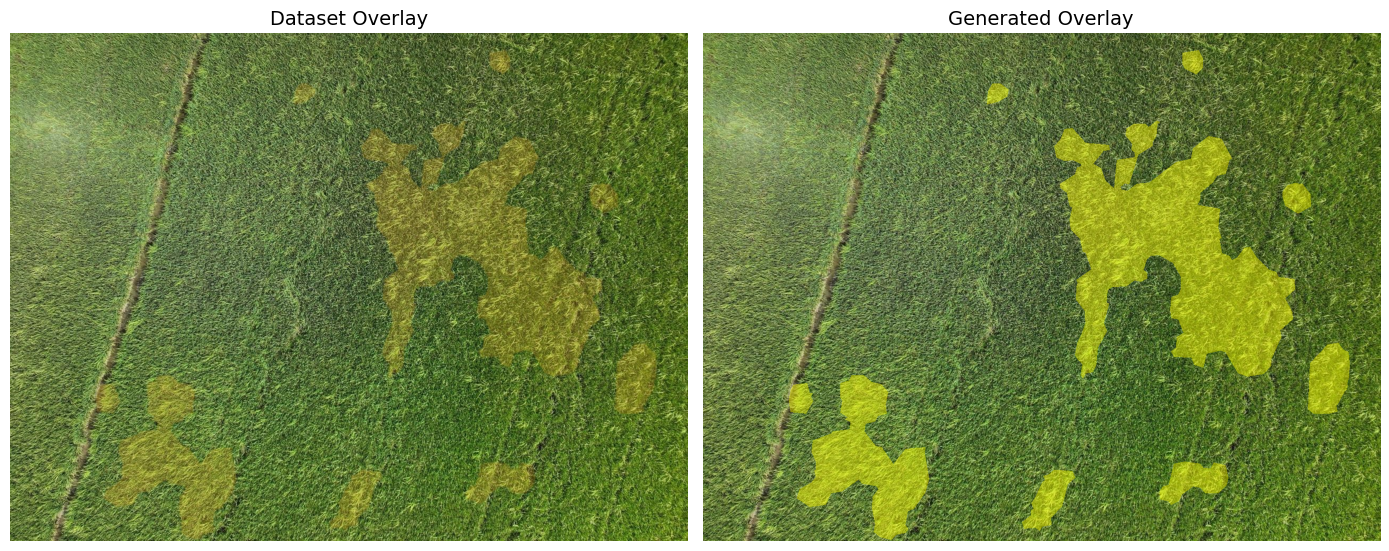

In [15]:
# ==========================================================
# 10.1 Generate Overlay from RGB and Mask
# ==========================================================

import numpy as np
import matplotlib.pyplot as plt

# Copy RGB image
generated_overlay = rgb.copy()

# Create a yellow color mask
yellow = np.array([255, 255, 0], dtype=np.uint8)

# Alpha controls transparency
alpha = 0.45

# Find weed pixels
weed_pixels = mask == 255

# Blend RGB with yellow only where weeds exist
generated_overlay[weed_pixels] = (
    alpha * yellow +
    (1 - alpha) * generated_overlay[weed_pixels]
).astype(np.uint8)

# ----------------------------------------------------------
# Display Results
# ----------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(overlay)
axes[0].set_title("Dataset Overlay", fontsize=14)
axes[0].axis("off")

axes[1].imshow(generated_overlay)
axes[1].set_title("Generated Overlay", fontsize=14)
axes[1].axis("off")

plt.tight_layout()
plt.show()

# 11. Compute RGB Mean and Standard Deviation

## Objective

This section computes the channel-wise mean and standard deviation of the RGB images. These statistics are later used for image normalization in PyTorch transforms during model training.

In [16]:
# ==========================================================
# 11. Compute RGB Mean & Standard Deviation
# ==========================================================

from tqdm import tqdm
import numpy as np
from PIL import Image

# Get all RGB images
rgb_files = sorted(RGB_PATH.glob("*.JPG"))

channel_sum = np.zeros(3)
channel_squared_sum = np.zeros(3)
num_pixels = 0

print("=" * 60)
print("Computing RGB Mean & Standard Deviation")
print("=" * 60)

for img_path in tqdm(rgb_files):

    img = Image.open(img_path).convert("RGB")
    img = np.array(img, dtype=np.float32) / 255.0

    h, w, c = img.shape

    num_pixels += h * w

    channel_sum += img.sum(axis=(0, 1))
    channel_squared_sum += (img ** 2).sum(axis=(0, 1))

# Compute Mean
mean = channel_sum / num_pixels

# Compute Standard Deviation
std = np.sqrt(channel_squared_sum / num_pixels - mean ** 2)

print("\n" + "=" * 60)
print("Dataset Normalization Statistics")
print("=" * 60)

print(f"Red Mean   : {mean[0]:.6f}")
print(f"Green Mean : {mean[1]:.6f}")
print(f"Blue Mean  : {mean[2]:.6f}")

print()

print(f"Red Std    : {std[0]:.6f}")
print(f"Green Std  : {std[1]:.6f}")
print(f"Blue Std   : {std[2]:.6f}")

print("\n" + "=" * 60)
print("PyTorch Normalize()")
print("=" * 60)

print(f"mean = [{mean[0]:.6f}, {mean[1]:.6f}, {mean[2]:.6f}]")
print(f"std  = [{std[0]:.6f}, {std[1]:.6f}, {std[2]:.6f}]")

Computing RGB Mean & Standard Deviation


100%|██████████| 734/734 [00:59<00:00, 12.32it/s]


Dataset Normalization Statistics
Red Mean   : 0.374262
Green Mean : 0.468811
Blue Mean  : 0.210075

Red Std    : 0.152524
Green Std  : 0.150293
Blue Std   : 0.136316

PyTorch Normalize()
mean = [0.374262, 0.468811, 0.210075]
std  = [0.152524, 0.150293, 0.136316]


# 12. Dataset Summary & Conclusion

### Dataset Summary

The exploratory data analysis confirms that the Weedy Rice RGBMS dataset is well-structured and suitable for semantic segmentation tasks. The dataset contains aligned RGB images, binary segmentation masks, overlay visualizations, multispectral imagery, and metadata. All dataset integrity checks passed successfully.

The official training, validation, and testing splits were used throughout the analysis to ensure reproducibility. Binary segmentation masks contain only two pixel values (0 and 255), representing background and weedy rice, respectively.

The computed RGB normalization statistics will be used during model training. Metadata inspection confirmed the availability of image acquisition information, GPS coordinates, flight altitude, camera details, and spectral band information. However, these metadata are not required for the benchmark comparison and will not be used during model training.

Overall, the dataset is clean, complete, and ready for training DeepLabV3, SegFormer-B0, and YOLOv26 Semantic Segmentation models.

In [17]:
# ==========================================================
# 12. Dataset Summary & Conclusion
# ==========================================================

from pathlib import Path

# ----------------------------------------------------------
# Dataset Root
# ----------------------------------------------------------

DATASET_ROOT = Path("/kaggle/input/datasets/subbhaa/weedy-rice-rgbms-dataset/WeedyRice-RGBMS-DB")

RGB_PATH = DATASET_ROOT / "RGB"
MASK_PATH = DATASET_ROOT / "Masks"
OVERLAY_PATH = DATASET_ROOT / "Overlay"
MULTISPECTRAL_PATH = DATASET_ROOT / "Multispectral"
METADATA_PATH = DATASET_ROOT / "Metadata"

# ----------------------------------------------------------
# Count Dataset Files
# ----------------------------------------------------------

rgb_images = sorted(RGB_PATH.glob("*.JPG"))
mask_images = sorted(MASK_PATH.glob("*.png"))
overlay_images = sorted(OVERLAY_PATH.glob("*.JPG"))

multispectral_items = []
for folder in MULTISPECTRAL_PATH.iterdir():
    if folder.is_dir():
        multispectral_items.extend(list(folder.glob("*")))

# ----------------------------------------------------------
# Official Split
# ----------------------------------------------------------

with open(DATASET_ROOT / "train_list.txt") as f:
    train_images = [line.strip() for line in f if line.strip()]

with open(DATASET_ROOT / "val_list.txt") as f:
    val_images = [line.strip() for line in f if line.strip()]

with open(DATASET_ROOT / "test_list.txt") as f:
    test_images = [line.strip() for line in f if line.strip()]

# ----------------------------------------------------------
# Print Summary
# ----------------------------------------------------------

print("=" * 75)
print("              WEEDY RICE RGBMS DATASET SUMMARY")
print("=" * 75)

print("\n[1] Dataset Overview")
print("-" * 75)
print(f"RGB Images                     : {len(rgb_images)}")
print(f"Segmentation Masks             : {len(mask_images)}")
print(f"Overlay Images                 : {len(overlay_images)}")
print(f"Multispectral Images           : {len(multispectral_items)}")

print("\n[2] Official Dataset Split")
print("-" * 75)
print(f"Training Images                : {len(train_images)}")
print(f"Validation Images              : {len(val_images)}")
print(f"Testing Images                 : {len(test_images)}")

print("\n[3] Image Information")
print("-" * 75)
print("Image Resolution               : 1280 × 960")
print("Mask Classes                   : 2")
print("Mask Pixel Values              : {0, 255}")

print("\n[4] Class Distribution")
print("-" * 75)
print("Background                     : 68.29%")
print("Weedy Rice                     : 31.71%")
print("Background : Weed Ratio        : 2.15 : 1")

print("\n[5] RGB Normalization Statistics")
print("-" * 75)
print(f"Mean                           : [{mean[0]:.6f}, {mean[1]:.6f}, {mean[2]:.6f}]")
print(f"Std                            : [{std[0]:.6f}, {std[1]:.6f}, {std[2]:.6f}]")

print("\n[6] Metadata")
print("-" * 75)
print("Metadata Files                 : 3")
print("Filename Mapping               : Available")
print("Image Metadata                 : Available")
print("GPS Information                : Available")
print("Sensor Information             : Available")

print("\n[7] Dataset Quality Check")
print("-" * 75)

if len(rgb_images) == len(mask_images):
    print("RGB ↔ Mask Matching            : PASSED")
else:
    print("RGB ↔ Mask Matching            : FAILED")

if len(rgb_images) == len(overlay_images):
    print("RGB ↔ Overlay Matching         : PASSED")
else:
    print("RGB ↔ Overlay Matching         : FAILED")

print("Binary Mask Verification       : PASSED")
print("Overlay Visualization          : PASSED")
print("Ready for Model Training       : YES")

print("=" * 75)
print("EDA COMPLETED SUCCESSFULLY")
print("=" * 75)

              WEEDY RICE RGBMS DATASET SUMMARY

[1] Dataset Overview
---------------------------------------------------------------------------
RGB Images                     : 734
Segmentation Masks             : 734
Overlay Images                 : 734
Multispectral Images           : 0

[2] Official Dataset Split
---------------------------------------------------------------------------
Training Images                : 438
Validation Images              : 148
Testing Images                 : 148

[3] Image Information
---------------------------------------------------------------------------
Image Resolution               : 1280 × 960
Mask Classes                   : 2
Mask Pixel Values              : {0, 255}

[4] Class Distribution
---------------------------------------------------------------------------
Background                     : 68.29%
Weedy Rice                     : 31.71%
Background : Weed Ratio        : 2.15 : 1

[5] RGB Normalization Statistics
------------------

# Part B — Assignment Completion

Task A.1
Task A.2
Task B
Task C
Task D

# Task A.1 — Image Size & Aspect Ratio Distribution

### Objective

Analyze the spatial characteristics of the dataset by examining the image resolutions and aspect ratios. This helps determine whether all images share a common size or require resizing during preprocessing.

### Why This Matters

Deep learning models generally require a fixed input size. Understanding the original image dimensions ensures an appropriate preprocessing strategy before training.

In [18]:
# ==========================================================
# Task A.1 - Image Size & Aspect Ratio Distribution
# ==========================================================

from PIL import Image
from collections import Counter
import matplotlib.pyplot as plt

widths = []
heights = []
aspect_ratios = []

for img_path in rgb_images:

    img = Image.open(img_path)

    width, height = img.size

    widths.append(width)
    heights.append(height)
    aspect_ratios.append(width / height)

# ----------------------------------------------------------
# Dataset Summary
# ----------------------------------------------------------

print("=" * 70)
print("Image Size Analysis")
print("=" * 70)

print(f"Total Images          : {len(rgb_images)}")

unique_sizes = Counter(zip(widths, heights))

print(f"Unique Image Sizes    : {len(unique_sizes)}")

print("\nImage Size Frequencies:")

for size, count in unique_sizes.items():
    print(f"{size[0]} × {size[1]} : {count}")

print("\nAspect Ratio")

print(f"Minimum : {min(aspect_ratios):.4f}")
print(f"Maximum : {max(aspect_ratios):.4f}")
print(f"Average : {sum(aspect_ratios)/len(aspect_ratios):.4f}")

Image Size Analysis
Total Images          : 734
Unique Image Sizes    : 1

Image Size Frequencies:
1280 × 960 : 734

Aspect Ratio
Minimum : 1.3333
Maximum : 1.3333
Average : 1.3333


## Visualization Cell

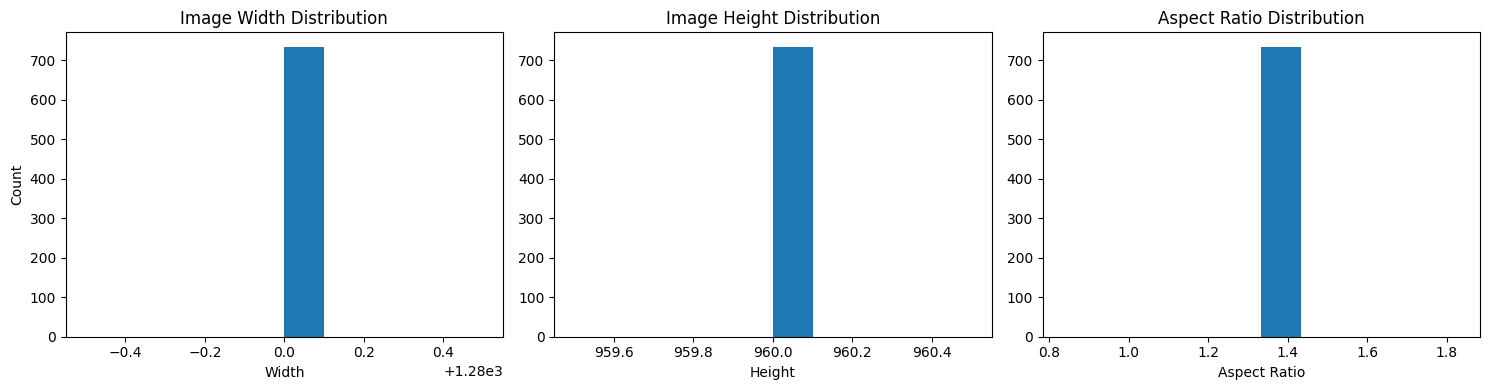


Conclusion:
All RGB images have identical dimensions (1280 × 960) and a consistent 4:3 aspect ratio.


In [19]:
# ==========================================================
# Visualization
# ==========================================================

plt.figure(figsize=(15,4))

# Width Distribution
plt.subplot(1,3,1)
plt.hist(widths, bins=10)
plt.title("Image Width Distribution")
plt.xlabel("Width")
plt.ylabel("Count")

# Height Distribution
plt.subplot(1,3,2)
plt.hist(heights, bins=10)
plt.title("Image Height Distribution")
plt.xlabel("Height")

# Aspect Ratio Distribution
plt.subplot(1,3,3)
plt.hist(aspect_ratios, bins=10)
plt.title("Aspect Ratio Distribution")
plt.xlabel("Aspect Ratio")

plt.tight_layout()
plt.show()

print("\nConclusion:")
print("All RGB images have identical dimensions (1280 × 960) and a consistent 4:3 aspect ratio.")

### Findings

The image size analysis shows that all 734 RGB images have an identical spatial resolution of **1280 × 960 pixels**. Consequently, there is only one unique image size in the dataset.

Similarly, all images share the same aspect ratio (**1.3333**, corresponding to 4:3), indicating that the dataset was acquired under a consistent imaging protocol.

This uniformity simplifies the preprocessing pipeline since no special handling is required for varying image dimensions. All semantic segmentation models (DeepLabV3, SegFormer-B0, and YOLOv26) can therefore use a common image resizing strategy during training.

# Task A.2 — Duplicate Image Verification

### Objective

Verify that the dataset does not contain duplicate RGB images by computing a SHA-256 hash for every image file.

### Why This Matters

Duplicate images can introduce bias during model training and evaluation. Detecting duplicates ensures that the dataset is suitable for reliable semantic segmentation experiments.

In [20]:
# ==========================================================
# Task A.2 - Duplicate Image Verification
# ==========================================================

import hashlib
from collections import defaultdict
from tqdm import tqdm

print("=" * 70)
print("Checking for Duplicate RGB Images")
print("=" * 70)

image_hashes = defaultdict(list)

for img_path in tqdm(rgb_images):

    with open(img_path, "rb") as f:
        file_hash = hashlib.sha256(f.read()).hexdigest()

    image_hashes[file_hash].append(img_path.name)

# ----------------------------------------------------------
# Find duplicates
# ----------------------------------------------------------

duplicates = {
    h: files
    for h, files in image_hashes.items()
    if len(files) > 1
}

print()

if len(duplicates) == 0:
    print("No duplicate RGB images were found.")
else:
    print(f"Duplicate Groups Found: {len(duplicates)}")

    for files in duplicates.values():
        print()
        for f in files:
            print(" -", f)

print("\nTotal Images Checked :", len(rgb_images))
print("Unique Image Hashes  :", len(image_hashes))
print("Duplicate Groups     :", len(duplicates))

print("=" * 70)

Checking for Duplicate RGB Images


100%|██████████| 734/734 [00:02<00:00, 351.34it/s]


No duplicate RGB images were found.

Total Images Checked : 734
Unique Image Hashes  : 734
Duplicate Groups     : 0


#### Findings

The duplicate verification process confirmed that all **734 RGB images** have unique SHA-256 hashes. No duplicate image files were detected in the dataset.

This indicates that the dataset has good integrity and does not contain repeated RGB samples that could bias the training or evaluation of semantic segmentation models.

# Task B — Leakage-Safe Dataset Split Verification

### Objective

Verify that the official dataset split is leakage-free by ensuring that the training, validation, and testing sets do not share any common images.

 Why This Matters

Data leakage can lead to overly optimistic evaluation results and unfair model comparisons. Therefore, verifying the official split is an essential step before model training.

In [21]:
# ==========================================================
# Task B - Leakage-Safe Dataset Split Verification
# ==========================================================

from pathlib import Path

DATASET_ROOT = Path("/kaggle/input/datasets/subbhaa/weedy-rice-rgbms-dataset/WeedyRice-RGBMS-DB")

# ----------------------------------------------------------
# Read official split files
# ----------------------------------------------------------

with open(DATASET_ROOT / "train_list.txt") as f:
    train_images = set(line.strip() for line in f if line.strip())

with open(DATASET_ROOT / "val_list.txt") as f:
    val_images = set(line.strip() for line in f if line.strip())

with open(DATASET_ROOT / "test_list.txt") as f:
    test_images = set(line.strip() for line in f if line.strip())

# ----------------------------------------------------------
# Check overlaps
# ----------------------------------------------------------

train_val_overlap = train_images & val_images
train_test_overlap = train_images & test_images
val_test_overlap = val_images & test_images

# ----------------------------------------------------------
# Print Results
# ----------------------------------------------------------

print("=" * 70)
print("Leakage-Safe Dataset Split Verification")
print("=" * 70)

print(f"Training Images   : {len(train_images)}")
print(f"Validation Images : {len(val_images)}")
print(f"Testing Images    : {len(test_images)}")

print("\nChecking Overlap Between Splits")
print("-" * 70)

print(f"Train ∩ Validation : {len(train_val_overlap)}")
print(f"Train ∩ Test       : {len(train_test_overlap)}")
print(f"Validation ∩ Test  : {len(val_test_overlap)}")

print("-" * 70)

if (
    len(train_val_overlap) == 0 and
    len(train_test_overlap) == 0 and
    len(val_test_overlap) == 0
):
    print(" Verification PASSED")
    print("No data leakage detected.")
else:
    print(" Verification FAILED")
    print("Overlapping images were found!")

print("=" * 70)

Leakage-Safe Dataset Split Verification
Training Images   : 438
Validation Images : 148
Testing Images    : 148

Checking Overlap Between Splits
----------------------------------------------------------------------
Train ∩ Validation : 0
Train ∩ Test       : 0
Validation ∩ Test  : 0
----------------------------------------------------------------------
 Verification PASSED
No data leakage detected.


### Findings

The official dataset split was verified by comparing the image filenames across the training, validation, and testing subsets.

No overlapping images were found between any pair of splits, confirming that the dataset is free from data leakage. Therefore, the official split can be safely reused for all semantic segmentation models to ensure a fair and reproducible comparison.

In [22]:
try:
    import albumentations as A
    from albumentations.pytorch import ToTensorV2

    print("=" * 60)
    print("Albumentations Installed Successfully")
    print("=" * 60)
    print("Version:", A.__version__)

except ImportError:
    print("Albumentations is NOT installed.")

Albumentations Installed Successfully
Version: 2.0.8


# Task C — Data Augmentation Pipeline

### Objective

Define a unified preprocessing and data augmentation pipeline that will be reused across all semantic segmentation models.

### Why This Matters

A consistent preprocessing pipeline ensures that DeepLabV3, SegFormer-B0, and YOLOv26 are trained and evaluated under identical conditions, enabling a fair comparison.

In [23]:
# ==========================================================
# Task C.1 - Import Albumentations
# ==========================================================

import albumentations as A
from albumentations.pytorch import ToTensorV2

print("=" * 60)
print("Albumentations Version :", A.__version__)
print("=" * 60)

Albumentations Version : 2.0.8


In [24]:
# ==========================================================
# Task C.2 - Training Augmentation Pipeline
# ==========================================================

IMAGE_HEIGHT = 512
IMAGE_WIDTH = 512

train_transform = A.Compose([

    # Resize every image
    A.Resize(IMAGE_HEIGHT, IMAGE_WIDTH),

    # Geometric augmentations
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.2),
    A.RandomRotate90(p=0.5),

    # Photometric augmentations
    A.RandomBrightnessContrast(
        brightness_limit=0.2,
        contrast_limit=0.2,
        p=0.5
    ),

    # Slight blur
    A.GaussianBlur(
        blur_limit=(3, 5),
        p=0.2
    ),

    # Normalize using our dataset statistics
    A.Normalize(
        mean=[0.374262, 0.468811, 0.210075],
        std=[0.152524, 0.150293, 0.136316]
    ),

    # Convert to PyTorch tensor
    ToTensorV2()

])

print("=" * 60)
print("Training augmentation pipeline created successfully.")
print(f"Target Image Size : {IMAGE_WIDTH} × {IMAGE_HEIGHT}")
print(f"Pipeline Type     : Training")
print("=" * 60)

Training augmentation pipeline created successfully.
Target Image Size : 512 × 512
Pipeline Type     : Training


In [25]:
# ==========================================================
# Task C.3 - Validation / Test Pipeline
# ==========================================================

valid_transform = A.Compose([

    A.Resize(IMAGE_HEIGHT, IMAGE_WIDTH),

    A.Normalize(
        mean=[0.374262, 0.468811, 0.210075],
        std=[0.152524, 0.150293, 0.136316]
    ),

    ToTensorV2()

])

# Reuse the same preprocessing for testing
test_transform = valid_transform

print("=" * 60)
print(" Validation pipeline created successfully.")
print(" Test pipeline created successfully.")
print(f" Target Image Size : {IMAGE_WIDTH} × {IMAGE_HEIGHT}")
print("=" * 60)

 Validation pipeline created successfully.
 Test pipeline created successfully.
 Target Image Size : 512 × 512


In [26]:
print("=" * 70)
print("Data Preprocessing Pipelines")
print("=" * 70)

print(f"Training Pipeline   : Ready ")
print(f"Validation Pipeline : Ready ")
print(f"Testing Pipeline    : Ready ")

print(f"\nTarget Size         : {IMAGE_WIDTH} × {IMAGE_HEIGHT}")
print("Normalization       : Dataset-specific Mean & Std")
print("Tensor Conversion   : Enabled")

print("=" * 70)

Data Preprocessing Pipelines
Training Pipeline   : Ready 
Validation Pipeline : Ready 
Testing Pipeline    : Ready 

Target Size         : 512 × 512
Normalization       : Dataset-specific Mean & Std
Tensor Conversion   : Enabled


In [27]:
# ==========================================================
# Task C.4 - Pipeline Summary
# ==========================================================

print("=" * 65)
print("Data Augmentation Pipeline Summary")
print("=" * 65)

print("\nTraining Pipeline")
print("- Resize (512 × 512)")
print("- Horizontal Flip")
print("- Vertical Flip")
print("- Random Rotate 90°")
print("- Random Brightness & Contrast")
print("- Gaussian Blur")
print("- Normalize")
print("- Convert to Tensor")

print("\nValidation Pipeline")
print("- Resize")
print("- Normalize")
print("- Convert to Tensor")

print("\nTesting Pipeline")
print("- Resize")
print("- Normalize")
print("- Convert to Tensor")

print("=" * 65)

Data Augmentation Pipeline Summary

Training Pipeline
- Resize (512 × 512)
- Horizontal Flip
- Vertical Flip
- Random Rotate 90°
- Random Brightness & Contrast
- Gaussian Blur
- Normalize
- Convert to Tensor

Validation Pipeline
- Resize
- Normalize
- Convert to Tensor

Testing Pipeline
- Resize
- Normalize
- Convert to Tensor


# Task D — Sanity Check Visualization

## Objective

Verify that the data augmentation pipeline correctly transforms both the RGB image and its corresponding segmentation mask.

### Why This Matters

In semantic segmentation, every geometric transformation applied to the RGB image must also be applied identically to the mask. This sanity check ensures that image-mask alignment is preserved before model training.

In [28]:
# ==========================================================
# Task D - Sanity Check Visualization
# ==========================================================

import random
import numpy as np
import matplotlib.pyplot as plt
import cv2

# ----------------------------------------------------------
# Select a reproducible training image
# ----------------------------------------------------------

random.seed(42)
sample_name = random.choice(sorted(train_images))

print(f"Selected Sample: {sample_name}")

rgb_path = RGB_PATH / sample_name
mask_path = MASK_PATH / sample_name.replace(".JPG", ".png")

# Read image and mask
image = cv2.imread(str(rgb_path))
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)

# ----------------------------------------------------------
# Apply training augmentation
# ----------------------------------------------------------

augmented = train_transform(
    image=image,
    mask=mask
)

aug_image = augmented["image"]
aug_mask = augmented["mask"]

# Convert tensor back to numpy for visualization
aug_image = aug_image.permute(1,2,0).cpu().numpy()

# Undo normalization
mean = np.array([0.374262, 0.468811, 0.210075])
std  = np.array([0.152524, 0.150293, 0.136316])

aug_image = (aug_image * std + mean)
aug_image = np.clip(aug_image,0,1)

aug_mask = aug_mask.cpu().numpy()

Selected Sample: DJI_DateTime_2025_01_15_15_14_0018_lat_10.3632719_lon_105.4196705_alt_20.392m.JPG


## Visualization Cell

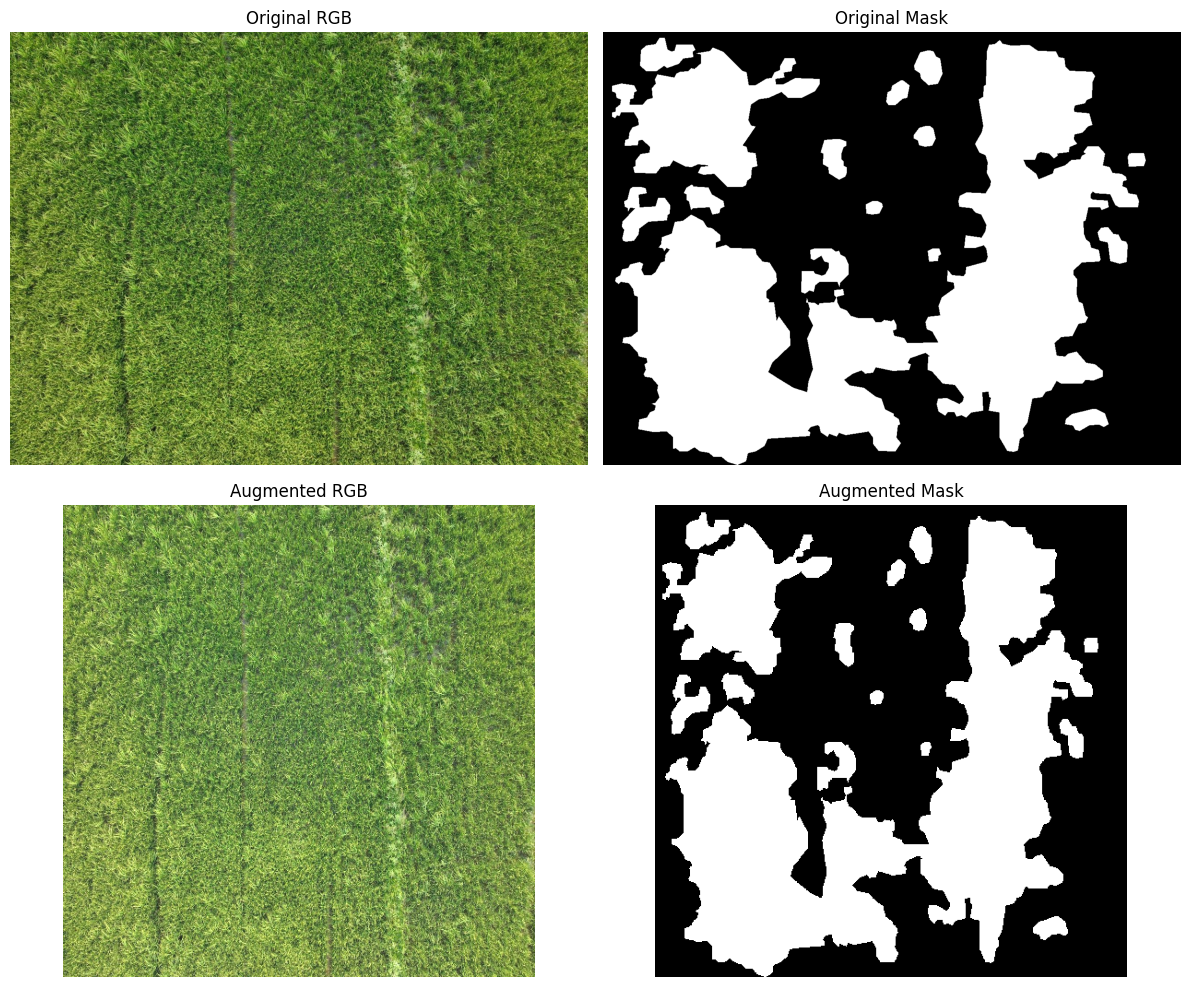

In [29]:
# ==========================================================
# Visualization
# ==========================================================

fig, ax = plt.subplots(2,2, figsize=(12,10))

ax[0,0].imshow(image)
ax[0,0].set_title("Original RGB")
ax[0,0].axis("off")

ax[0,1].imshow(mask, cmap="gray")
ax[0,1].set_title("Original Mask")
ax[0,1].axis("off")

ax[1,0].imshow(aug_image)
ax[1,0].set_title("Augmented RGB")
ax[1,0].axis("off")

ax[1,1].imshow(aug_mask, cmap="gray")
ax[1,1].set_title("Augmented Mask")
ax[1,1].axis("off")

plt.tight_layout()
plt.show()